In [88]:
import numpy as np
from numpy.random import randn
from scipy.linalg import sqrtm, inv, norm
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import chi2

In [89]:
def epsilon_and_nu(P: float, Sigma: np.ndarray):
    nu = 1/ (2 * np.pi * np.sqrt(np.linalg.det(Sigma)))
    epsilon = (1-P) * nu

    return epsilon, nu

def in_error_ellipse(x: np.ndarray, mu: np.ndarray, Sigma: np.ndarray, P=0.95):
    epsilon, nu = epsilon_and_nu(P, Sigma)
    rhs = -2*np.log(epsilon / nu)   # = -2 log(1-P)
    lhs = (x - mu).T @ np.linalg.inv(Sigma) @ (x - mu)
    return lhs <= rhs
    
def plot_gaussian(mu, Sigma, N):
    x_arr = randn(N,2) @ sqrtm(Sigma) + mu

    x_in = np.array([x for x in x_arr if in_error_ellipse(x, mu, Sigma)])
    x_out = np.array([x for x in x_arr if not in_error_ellipse(x, mu, Sigma)])

    e, _ = epsilon_and_nu(0.95, Sigma)
    print(f"Percentage of points in ellipse {len(x_in) / N * 100}")
    plt.scatter(x_in[:,0], x_in[:,1], marker='.')
    plt.scatter(x_out[:,0], x_out[:,1], marker='.')
    plt.title("95% Confidence Error Ellipse")
    plt.show()

def get_ellipse_points(mu: np.ndarray, Sigma: np.ndarray, P=0.95, N=200):
    t = np.linspace(0, 2*np.pi, N)
    circle = np.vstack((np.cos(t), np.sin(t)))
    rhs = -2*np.log(1-P)
    ellipse = np.sqrt(rhs) * circle
    scaled_ellipse = sqrtm(Sigma) @ ellipse # circle -> ellipse
    return scaled_ellipse + mu.reshape(2,1)

Percentage of points in ellipse 95.3


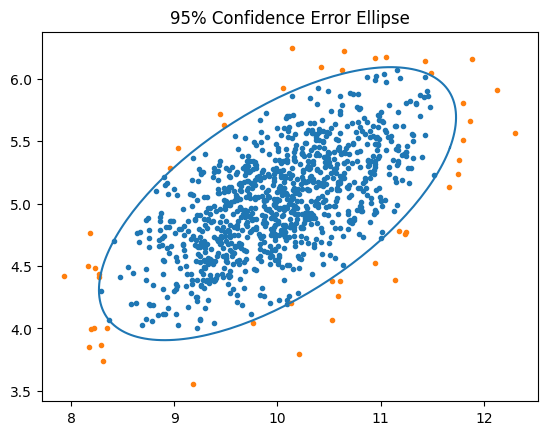

In [90]:
mu_1 = np.array([10,5])
Sigma_1 = np.array([
    [0.5, 0.2],[0.2, 0.2]
])



plt.plot(*get_ellipse_points(mu_1, Sigma_1))
plot_gaussian(mu_1, Sigma_1, 1000)


Percentage of points in ellipse 93.89999999999999


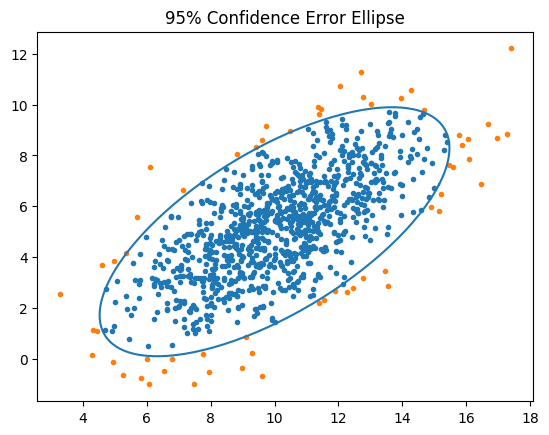

In [91]:
mu_2 = np.array([10,5])
Sigma_2 = np.array([
    [5, 3],[3, 4]
])

plt.plot(*get_ellipse_points(mu_2, Sigma_2))
plot_gaussian(mu_2, Sigma_2, 1000)

Percentage of points in ellipse 96.8


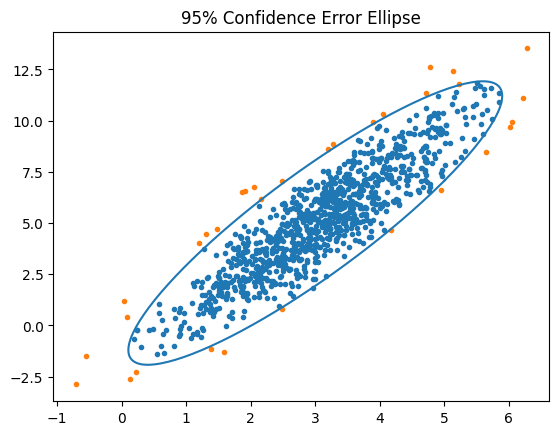

In [92]:
mu_3 = np.array([3,5])
Sigma_3 = np.array([
    [1.4, 3],[3, 8]
])

plt.plot(*get_ellipse_points(mu_3, Sigma_3))
plot_gaussian(mu_3, Sigma_3, 1000)